In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pandas as pd
import numpy as np
from utils.load_splits import load_splits
from utils.eval_tools import compare_models, bootstrap_compare, compare_by_segment, plot_comparison, plot_segments, plot_bootstrap, plot_tradeoff
from models.popularity import PopularityModel
from models.cat_pop import CategoryPopularityModel
from models.itemCFv2 import ItemCFModel
from models.blend_user_discovery import BlendModel

In [3]:
train_raw, val_raw, test_raw=load_splits(
    train_path="../../data/split/train.parquet",
    val_path="../../data/split/val.parquet",
    test_path="../../data/split/test.parquet",
)

train = train_raw[train_raw['sales_channel_id']==2]
val = val_raw[val_raw['sales_channel_id']==2]
test = test_raw[test_raw['sales_channel_id']==2]

In [4]:
articles=pd.read_parquet("../../data/cleaned_art.parquet")
pc = articles.set_index("article_id")["product_code"] #product code
types = articles.set_index("article_id")["product_type_no"] #product type

In [5]:
models = {
    "pop_discovery": PopularityModel(exclude_seen=True),
    "cat_pop": CategoryPopularityModel(types),
    "cf_lastday_nocolour": ItemCFModel(types, allow_same_category=True, source="last_day",
                                       exclude_owned_product_code=True, article_product=pc),
}
comps = {"cat_pop": models["cat_pop"], "cf": models["cf_lastday_nocolour"]}
for w in (0.3, 0.5, 0.7):          # share given to cat_pop
    models[f"blend_w{w}"] = BlendModel(comps, weights={"cat_pop": w, "cf": 1 - w},
                                       rrf_c=10, fit_components=False, k=12)

In [6]:
summary, per_user = compare_models(models, train, val, baseline="cat_pop",
                                   problem="discovery", k=12)

Setup: user_group=warm, truth_mode=novel -> 7,358 users, 27,569 relevant purchases
        14.9% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating pop_discovery ...
Evaluating cat_pop ...
Evaluating cf_lastday_nocolour ...
Evaluating blend_w0.3 ...
Evaluating blend_w0.5 ...
Evaluating blend_w0.7 ...


In [7]:
ci_df, paired_df=bootstrap_compare(per_user,baseline="cat_pop", k=12)

In [8]:
summary.to_csv("results/model_comparison_v2.csv")
paired_df.to_csv("results/paired_ci_df_v2.csv")

### **PLOTTING**

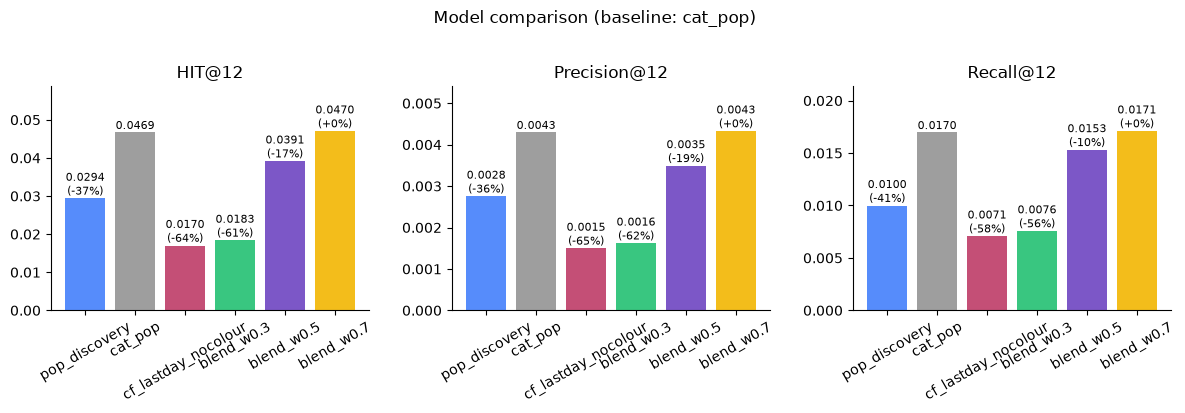

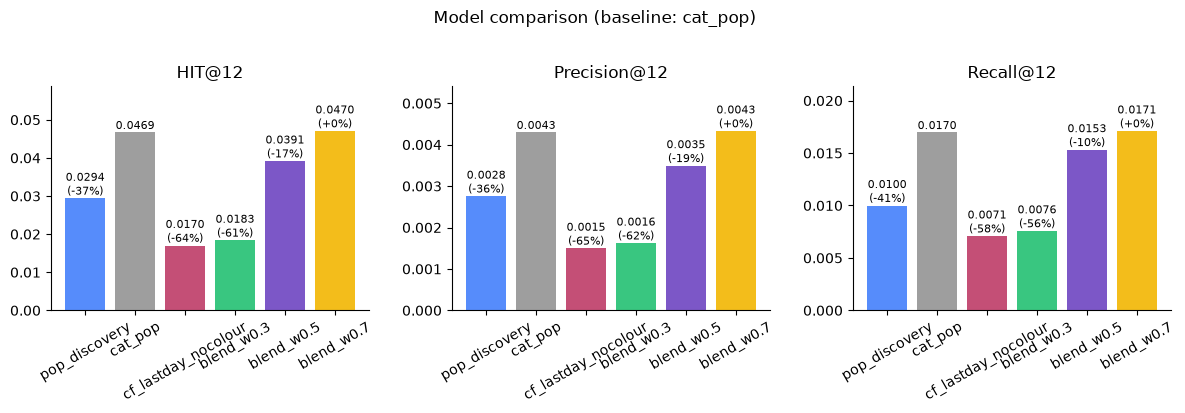

In [13]:
plot_comparison(summary, baseline="cat_pop", k=12)

,segment,metric,model,mean,ci_low,ci_high
0,all,HIT@12,blend_w0.3,0.018347,0.015086,0.021473
1,all,HIT@12,blend_w0.5,0.039141,0.035064,0.043762
2,all,HIT@12,blend_w0.7,0.047024,0.042539,0.051916
3,all,HIT@12,cat_pop,0.046888,0.042403,0.051644
4,all,HIT@12,cf_lastday_nocolour,0.016988,0.014134,0.019978
5,all,HIT@12,pop_discovery,0.029356,0.025822,0.033161
6,all,Precision@12,blend_w0.3,0.001620,0.001325,0.001914
7,all,Precision@12,blend_w0.5,0.003488,0.003103,0.003907
8,all,Precision@12,blend_w0.7,0.004326,0.003907,0.004779
9,all,Precision@12,cat_pop,0.004315,0.003896,0.004757


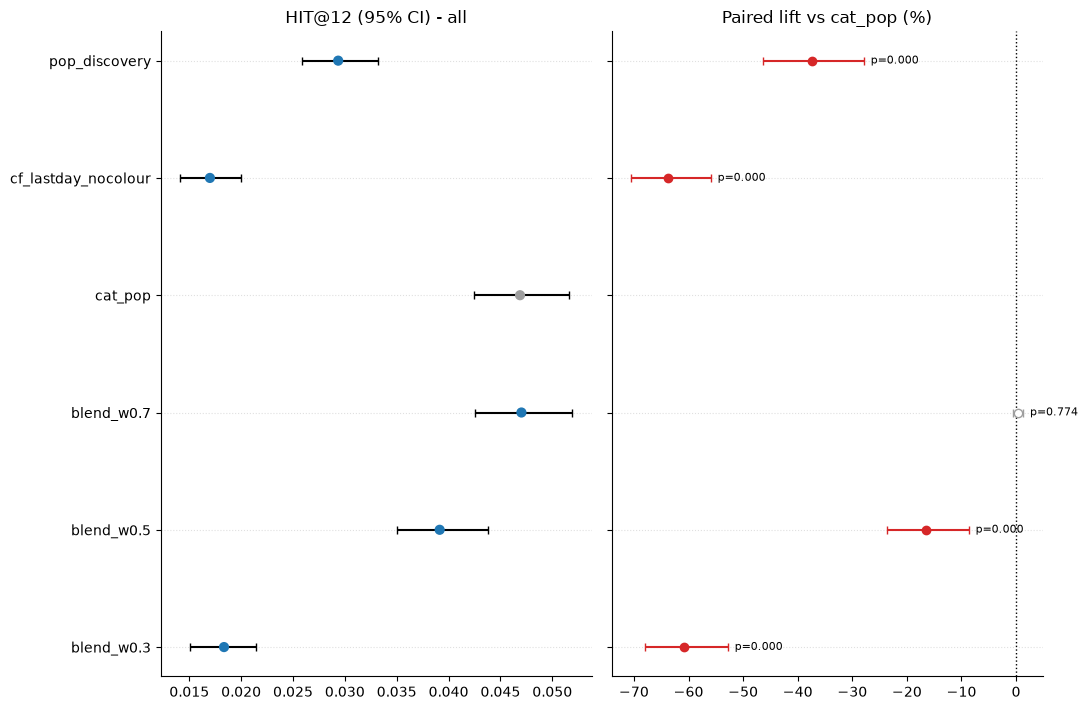

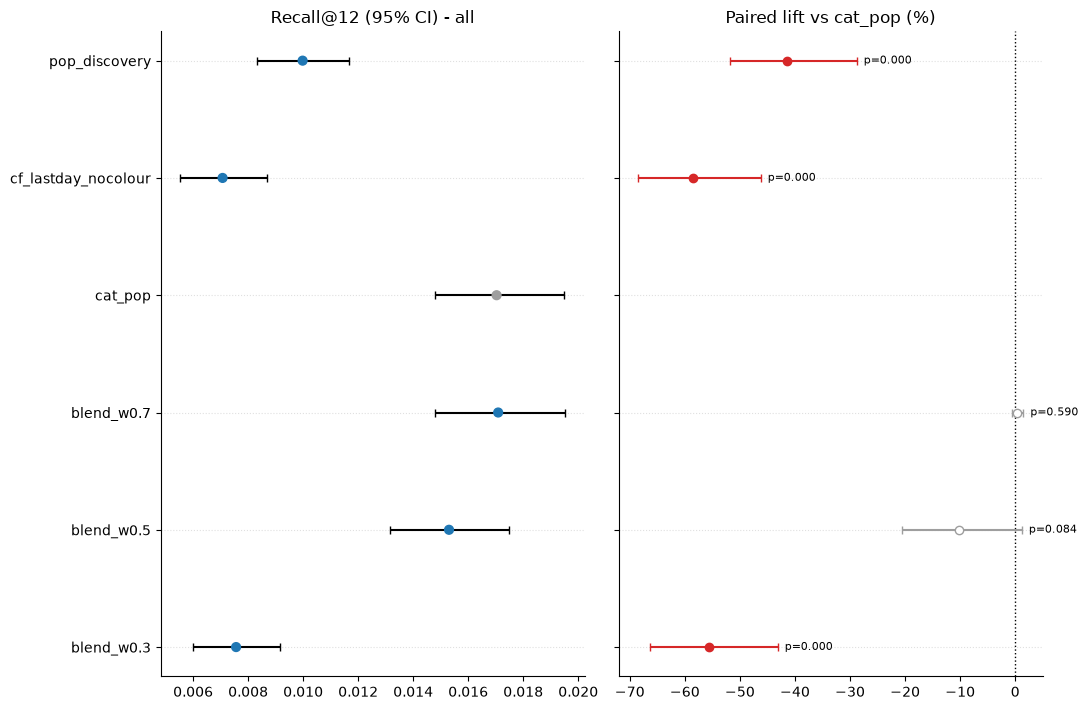

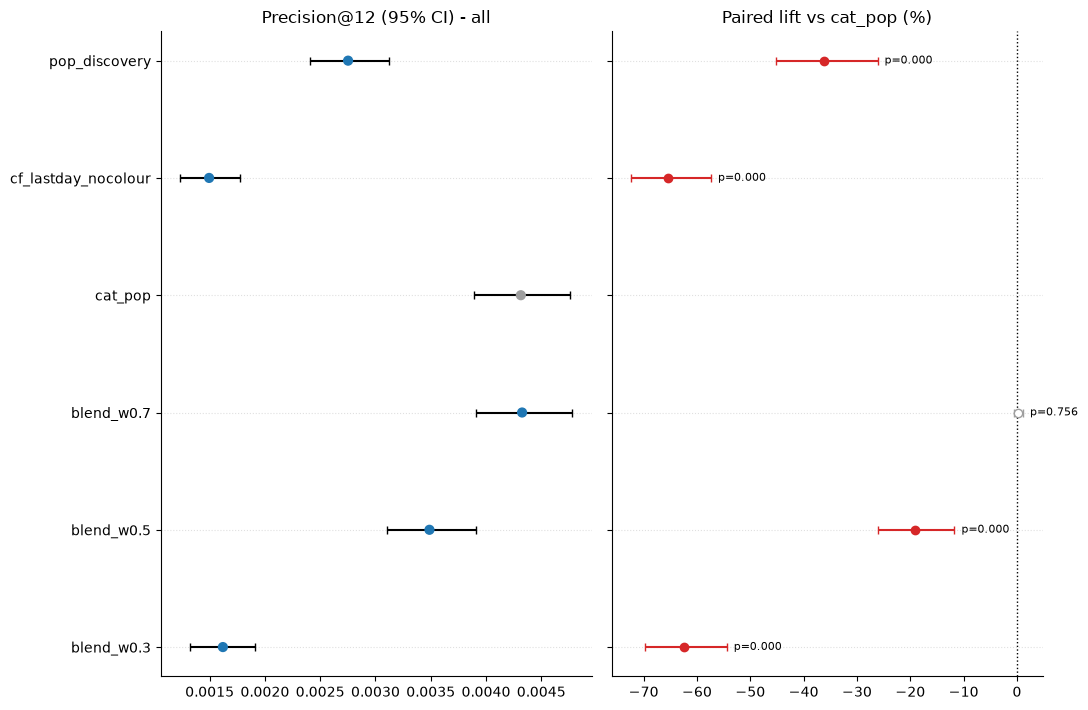

In [14]:
metrics=["HIT", "Recall", "Precision"]
for metric in metrics:
    plot_bootstrap(ci_df,paired_df,baseline="cat_pop", metric=metric)

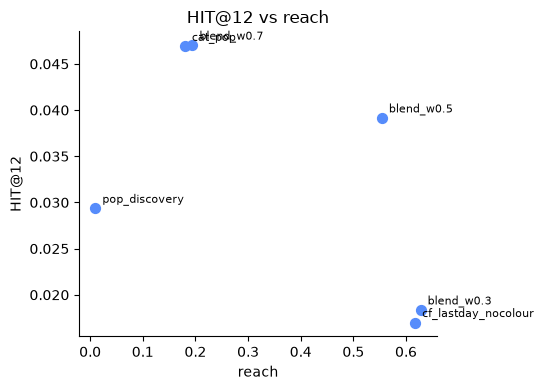

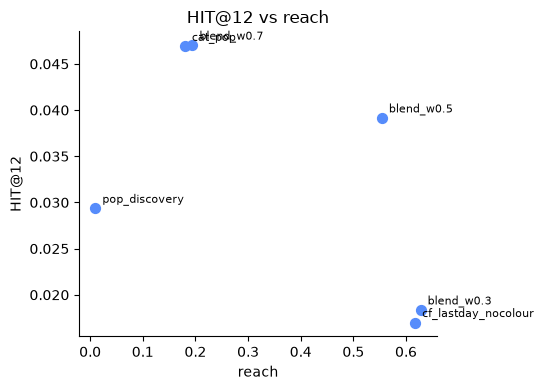

In [15]:
plot_tradeoff(summary, x="reach")

In [10]:
final_models={
    "cat_pop": CategoryPopularityModel(types),
}

for w in (0.55, 0.6, 0.65):          # share given to cat_pop
    final_models[f"blend_w{w}"] = BlendModel(comps, weights={"cat_pop": w, "cf": 1 - w},
                                       rrf_c=10, fit_components=False, k=12)

In [11]:
summary_v2, per_user_v2=compare_models(final_models, train, val, baseline="cat_pop",k=12, problem="discovery")

Setup: user_group=warm, truth_mode=novel -> 7,358 users, 27,569 relevant purchases
        14.9% of relevant purchases are articles never seen in history (no history-based model can reach them)
Evaluating cat_pop ...
Evaluating blend_w0.55 ...
Evaluating blend_w0.6 ...
Evaluating blend_w0.65 ...


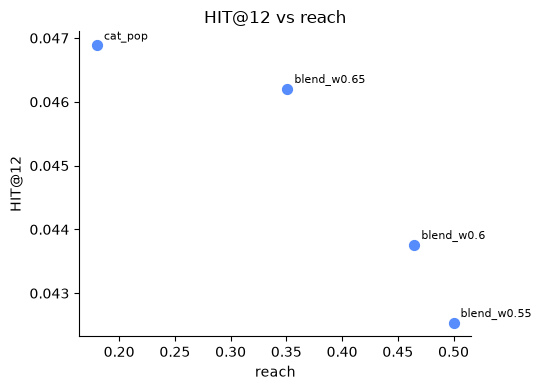

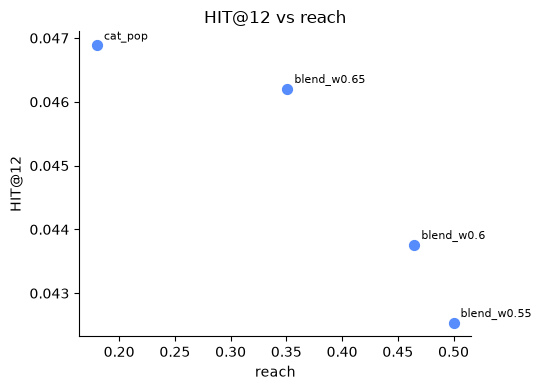

In [47]:
plot_tradeoff(summary_v2, x="reach")

In [12]:
ci_df_v2, paired_df_v2=bootstrap_compare(per_user_v2,baseline="cat_pop", k=12)

In [13]:
summary_v2.to_csv("results/model_comparsion_v3.csv")
paired_df_v2.to_csv("results/paired_ci_df_v3.csv")

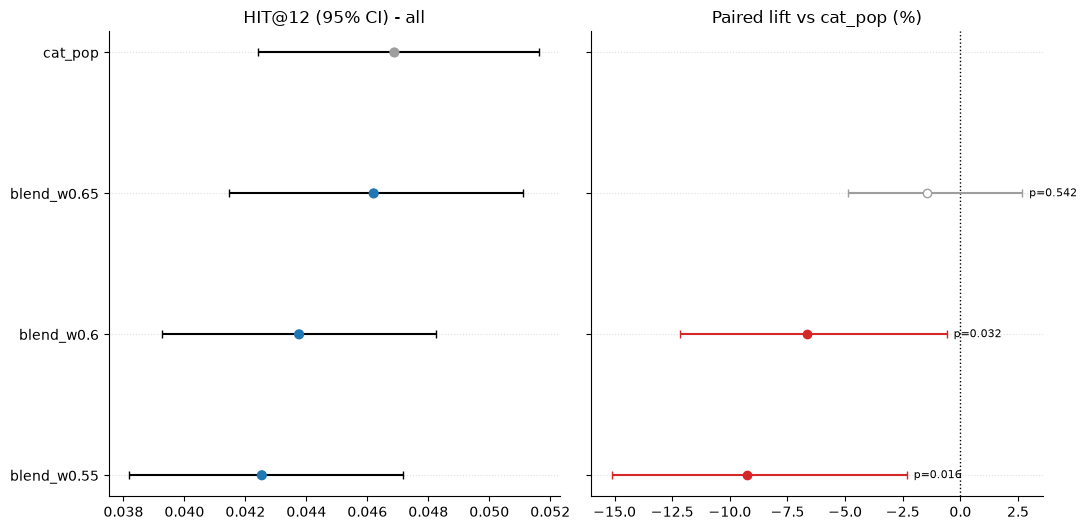

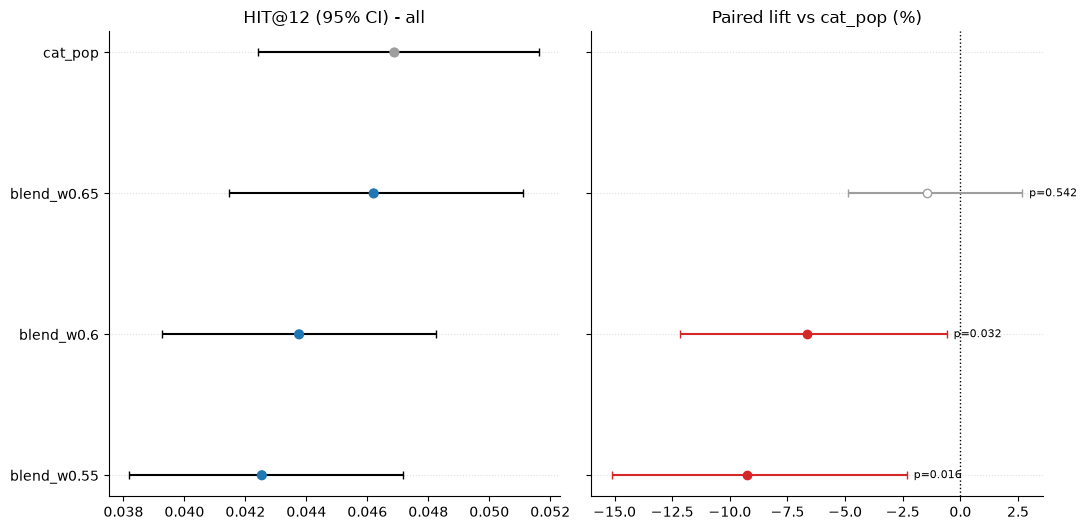

In [51]:
plot_bootstrap(ci_df_v2, paired_df_v2, baseline="cat_pop", metric="HIT")

### CONCLUSION: WHAT MODEL WEIGHT PICKED?

Which one to choose

0.65 is the most efficient point, and I’d expect its paired CI to include 0, which means you could say it is **statistically comparable** to cat_pop with nearly 2× the reach. That is the safest claim for a coursework.

0.6 is the right pick if discovery is the stated goal of your project. It gets most of the available reach (about 93% of what 0.55 gets) at a cost of about 6–7% HIT, which your earlier bootstrap showed is small but borderline significant.

Your 0.6 is therefore reasonable, but it is a decision about priorities, not a result the data forces.

### Limitations and Caveats: Colour-Variant Blocking (exclude_owned_product_code)

#### Overview
Colour-variant blocking is a collaborative filtering (CF) feature designed to prevent recommending different colour options of products a user already owns. It was introduced because 42%–53% of CF recommendations were colour variants, whereas they accounted for only 4.7% of actual purchases.

#### Key Observation
* **Sharp Performance Drop:** Enabling the block caused HIT@4 for last-day CF to fall by **54%** (dropping from 0.0192 to 0.0088 users with a hit).
* This disproved the initial hypothesis that colour variants were uselessly occupying slots that other articles would fill better.

---

#### Main Limitations & Caveats
* **Flawed Initial Reasoning:** The hypothesis compared recommendation shares to purchase shares instead of evaluating the hit rate per recommended slot. Colour variants turned out to be highly productive slots.
* **Unisolated Causes:** The performance drop was not broken down to see if it stemmed from losing productive slots, refilling them with weaker items, or a combination of both.
* **Lack of Statistical Rigor:** The comparison relied on raw numbers without direct significance testing.
* **Narrow Testing Window:** The feature was validated on only one week of data, which can easily mislead.
* **Metric Blind Spots:** The evaluation relied strictly on accuracy metrics (HIT, Precision, Recall) and ignored qualitative factors like perceived repetition or user annoyance.
* **Premature Default:** The feature was set as a pipeline default based on blend experiments rather than isolated validation.

---

#### Proposed Future Work
* **Direct Hit-Rate Analysis:** Compare the hit rates of colour variants and other articles directly.
* **Refined Filtering:** Move away from full blocking to soft approaches, such as keeping at most one colour variant per product or selecting colours based on user habits.
* **Product-Level CF:** Compute similarity by merging colours first, then choosing the specific colour afterward.
* **Expanded Validation:** Re-run tests over multiple validation weeks for both isolated CF and blended models.
* **Qualitative Metrics:** Integrate measures for diversity and perceived relevance alongside standard accuracy metrics.